# 1.2 Continuous beams: Clapeyron three-moment equation

A continuous beam on n + 1 supports has more unknown reactions than equilibrium equations, so a **compatibility** condition is needed at every interior support:
the slope of the two spans meeting there must be equal.

*Reference:* NPTEL, *Structural Analysis II*, Lessons 12 and 13 (IIT Kharagpur).

In [2]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## The equation

Treat each span as simply supported (free bending moment diagram of area $A$) and add the unknown support moments $M_L, M_C, M_R$ (sagging positive).
Slope continuity at C, unyielding supports, different second moments of area:

$$\frac{M_L l_L}{I_L} + 2M_C\left(\frac{l_L}{I_L}+\frac{l_R}{I_R}\right) + \frac{M_R l_R}{I_R} = -\frac{6A_L\bar x_L}{l_L I_L} - \frac{6A_R\bar x_R}{l_R I_R}$$

$\bar x_L$ is measured from the **left** end of the left span and $\bar x_R$ from the **right** end of the right span.

| Load on the span | $6A\bar x/l$ measured from the left end | measured from the right end |
|:--|:-:|:-:|
| UDL w over the whole span | $wl^3/4$ | $wl^3/4$ |
| Point load P at a from left, b from right | $Pab(l+a)/l$ | $Pab(l+b)/l$ |

A **fixed end** is replaced by an imaginary span of zero length (NPTEL Example 12.2). An **overhang** gives a known end moment.

Once the support moments are known: $M(x) = M_0(x) + M_i(1 - x/l) + M_{i+1}\,x/l$ and $V(x) = V_0(x) + (M_{i+1}-M_i)/l$.

## Example 1: NPTEL Example 12.1 (benchmark)

Two 10 m spans, 1 kN/m throughout, 10 kN at the middle of AB, and a known overhang moment of −15 kN·m at C.

## Two-span beam, NPTEL Example 12.1

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Three-moment equation

### Hand solution

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $l$ | $l = 10$ m |
|  | $w$ | $w = 1$ kN/m |
|  | $P$ | $P = 10$ kN |
|  | Overhang moment at C: $M_{C}$ | $M_{C} = -15$ kN·m |
| Load table | UDL term, each span<br>$T_{1} = \dfrac{w\,l^{3}}{4}$<br>$\quad = \dfrac{1\times 10^{3}}{4}$ | $\mathbf{T_{1} = 250}$ |
| Load table | Point load term, span AB<br>$T_{2} = \dfrac{P\,\dfrac{l}{2}\,\dfrac{l}{2}\,\left(l + \dfrac{l}{2}\right)}{l}$<br>$\quad = \dfrac{10\times \dfrac{10}{2}\times \dfrac{10}{2}\times \left(10 + \dfrac{10}{2}\right)}{10}$ | $\mathbf{T_{2} = 375}$ |
| NPTEL L12, M_A = 0 | $M_{B} = \dfrac{-T_{1} - T_{2} - T_{1} - M_{C}\,l}{2\,\left(l + l\right)}$<br>$\quad = \dfrac{-250 - 375 - 250 - (-15)\times 10}{2\times \left(10 + 10\right)}$ | $\mathbf{M_{B} = -18.12}$ kN·m |
| NPTEL Ex. 12.1 | Published answer: $M_{ref}$ | $M_{ref} = -18.12$ kN·m |
|  | **Check:** matches the published support moment | ✅ **PASS** |
| Equilibrium of AB | $R_{A} = \dfrac{w\,l}{2} + \dfrac{P}{2} + \dfrac{M_{B}}{l}$<br>$\quad = \dfrac{1\times 10}{2} + \dfrac{10}{2} + \dfrac{(-18.12)}{10}$ | $\mathbf{R_{A} = 8.188}$ kN |
| Equilibrium of AB | $R_{BL} = w\,l + P - R_{A}$<br>$\quad = 1\times 10 + 10 - 8.188$ | $\mathbf{R_{BL} = 11.81}$ kN |
| Equilibrium of BC | $R_{BR} = \dfrac{w\,l}{2} + \dfrac{M_{C} - M_{B}}{l}$<br>$\quad = \dfrac{1\times 10}{2} + \dfrac{(-15) - (-18.12)}{10}$ | $\mathbf{R_{BR} = 5.312}$ kN |
| Equilibrium of BC | $R_{C} = w\,l - R_{BR}$<br>$\quad = 1\times 10 - 5.312$ | $\mathbf{R_{C} = 4.688}$ kN |
|  | NPTEL prints R_C = 4.7125 kN, but R_BR + R_C must equal the 10 kN on the span, so 4.6875 kN is correct. |  |


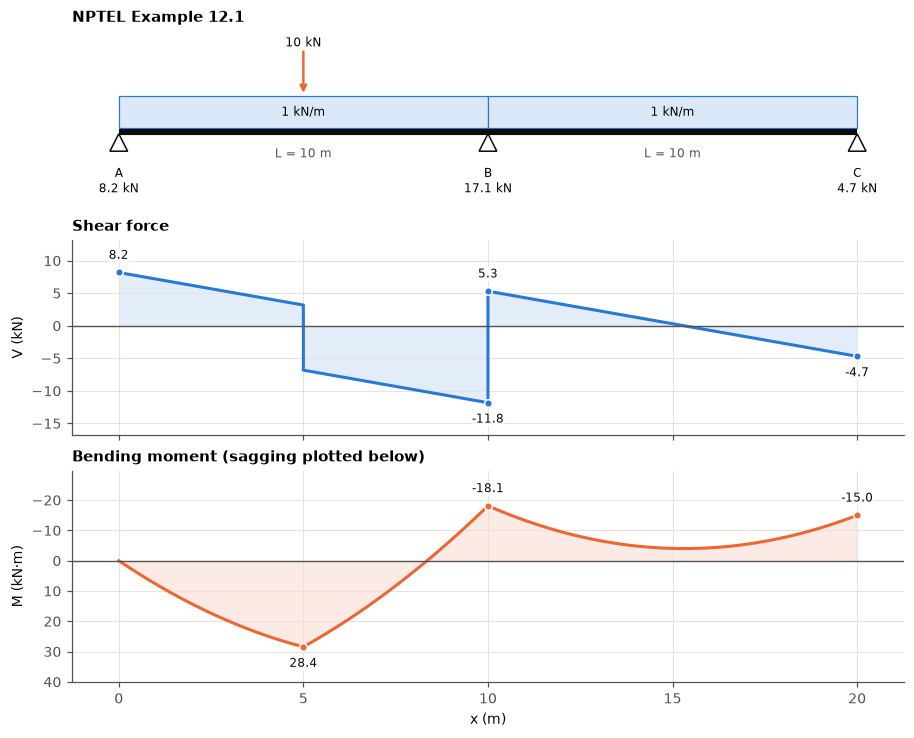

In [3]:
s = Sheet("Two-span beam, NPTEL Example 12.1", element="Three-moment equation")
s.let("l", 10, "m"); s.let("w", 1, "kN/m"); s.let("P", 10, "kN"); s.let("M_C", -15, "kN·m", "Overhang moment at C")
s.calc("T_1", "w*l**3/4", "", "Load table", "UDL term, each span")
s.calc("T_2", "P*(l/2)*(l/2)*(l + l/2)/l", "", "Load table", "Point load term, span AB")
s.calc("M_B", "(-T_1 - T_2 - T_1 - M_C*l)/(2*(l + l))", "kN·m", "NPTEL L12, M_A = 0")
s.let("M_ref", -18.125, "kN·m", "Published answer", "NPTEL Ex. 12.1")
s.verdict(abs(s["M_B"] + 18.125) < 1e-9, "matches the published support moment")
s.calc("R_A", "w*l/2 + P/2 + M_B/l", "kN", "Equilibrium of AB")
s.calc("R_BL", "w*l + P - R_A", "kN", "Equilibrium of AB")
s.calc("R_BR", "w*l/2 + (M_C - M_B)/l", "kN", "Equilibrium of BC")
s.calc("R_C", "w*l - R_BR", "kN", "Equilibrium of BC")
s.note("NPTEL prints R_C = 4.7125 kN, but R_BR + R_C must equal the 10 kN on the span, so 4.6875 kN is correct.")
s.show("Hand solution")
cb = ContinuousBeam([Span(10, [UDL(1), Point(10, 5)]), Span(10, [UDL(1)])], right=-15)
cb.three_moment(); cb.diagrams(); P.continuous(cb, "NPTEL Example 12.1")

## Example 2: three unequal spans

The program writes one equation per interior support and solves them together.

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `ex2_spans` | Spans from left to right | m, kN | list of `Span(...)` |

`UVL` and `Moment` are not accepted here.

**Writing spans and loads**

| Write | Meaning | Units |
|:--|:--|:--|
| `Point(P, a)` | Downward load P at a from the left end of its span | kN, m |
| `UDL(w)` or `UDL(w, a, b)` | Uniform load, over the whole span or from a to b | kN/m, m |
| `Span(L, [loads], I)` | One span; `I` is relative and optional | m |

Capital letters matter, and all loads of a span go inside one list: `Span(5.0, [UDL(20), Point(20, 3.4)])`.

**Not checked:** a load beyond its span, or a larger than b, runs without an error and gives wrong answers. A negative load means upward.

In [18]:
# INPUTS: edit only this cell, then run the cells below it
ex2_spans = [Span(6.0, [UDL(30)]), Span(6.0, [UDL(20), Point(40, 3.0)]), Span(4.0, [UDL(20)])]     # m, kN/m, kN

## Three-span beam

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Three-moment equation

### Equations and solution

| Reference | Calculation | Output |
|:--|:--|:--|
| Load table | Span AB: $6A\bar x/l$ from left = 1620.00, from right = 1620.00 |  |
| Load table | Span BC: $6A\bar x/l$ from left = 1620.00, from right = 1620.00 |  |
| Load table | Span CD: $6A\bar x/l$ from left = 320.00, from right = 320.00 |  |
| NPTEL L12 | Support B: $6\,M_{A} + 24\,M_{B} + 6\,M_{C} = -3240$ |  |
| NPTEL L12 | Support C: $6\,M_{B} + 20\,M_{C} + 4\,M_{D} = -1940$ |  |
|  | Support moment: $M_{A}$ | $M_{A} = 0$ kN·m |
|  | Support moment: $M_{B}$ | $M_{B} = -119.7$ kN·m |
|  | Support moment: $M_{C}$ | $M_{C} = -61.08$ kN·m |
|  | Support moment: $M_{D}$ | $M_{D} = 0$ kN·m |
|  | Reaction: $R_{A}$ | $R_{A} = 70.05$ kN |
|  | Reaction: $R_{B}$ | $R_{B} = 199.7$ kN |
|  | Reaction: $R_{C}$ | $R_{C} = 125.5$ kN |
|  | Reaction: $R_{D}$ | $R_{D} = 24.73$ kN |
|  | Total load: $W_{tot}$ | $W_{tot} = 420$ kN |
|  | Sum of reactions: $R_{tot}$ | $R_{tot} = 420$ kN |
|  | **Check:** vertical equilibrium ΣR = ΣW | ✅ **PASS** |


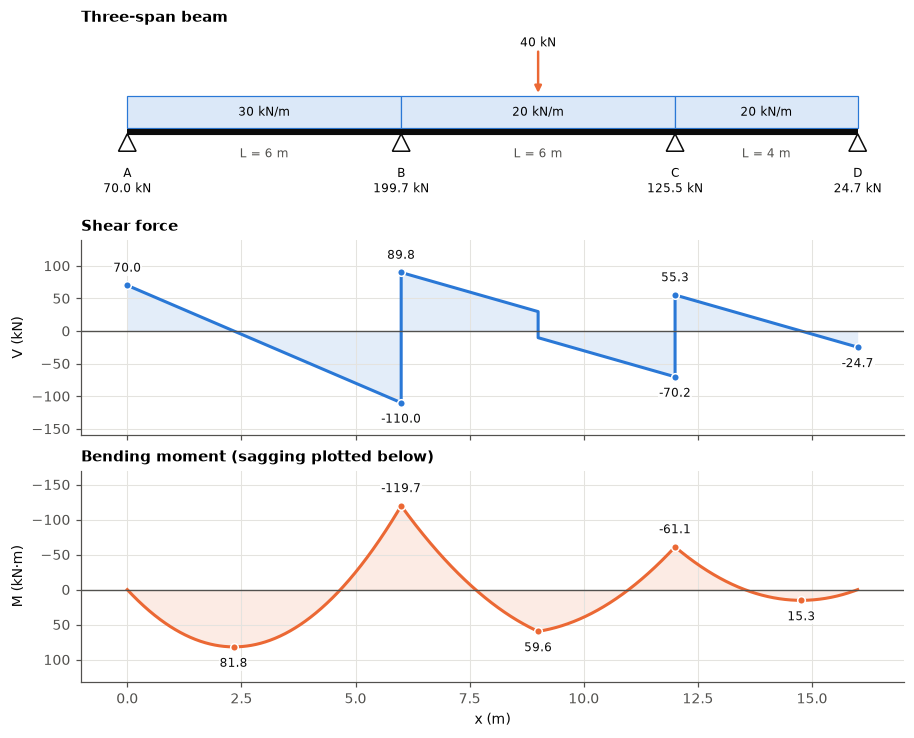

In [19]:
cb = ContinuousBeam(ex2_spans)
M = cb.three_moment(); cb.diagrams()
s = Sheet("Three-span beam", element="Three-moment equation")
for i, sp in enumerate(ex2_spans):
    l, r = sp.three_moment_terms()
    s.note(f"Span {cb.names[i]}{cb.names[i+1]}: $6A\\bar x/l$ from left = {l:.2f}, from right = {r:.2f}", "Load table")
for n, e in cb.equations:
    s.note(f"Support {n}: ${e}$", "NPTEL L12")
for n, m in zip(cb.names, M):
    s.let(f"M_{n}", float(m), "kN·m", "Support moment")
for n, r in zip(cb.names, cb.R):
    s.let(f"R_{n}", float(r), "kN", "Reaction")
W_tot = sum((q.P if isinstance(q, Point) else q.w * ((sp.L if q.b is None else q.b) - q.a)) for sp in ex2_spans for q in sp.loads)
s.let("W_tot", W_tot, "kN", "Total load"); s.let("R_tot", float(sum(cb.R)), "kN", "Sum of reactions")
s.verdict(abs(sum(cb.R) - W_tot) < 1e-6, "vertical equilibrium ΣR = ΣW")
s.show("Equations and solution")
P.continuous(cb, "Three-span beam")

## Example 3: fixed end and different I (NPTEL Example 12.2 data)

## Propped two-span beam

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Three-moment equation

### Equations and solution

| Reference | Calculation | Output |
|:--|:--|:--|
| NPTEL L12, imaginary span at the fixed end | Support A: $10\,M_{A} + 5\,M_{B} = -250$ |  |
| NPTEL L12, imaginary span at the fixed end | Support B: $5\,M_{A} + 20\,M_{B} + 5\,M_{C} = -312.5$ |  |
|  | $M_{A}$ | $M_{A} = -19.64$ kN·m |
|  | $M_{B}$ | $M_{B} = -10.71$ kN·m |
|  | These are the same two equations as NPTEL (4) and (5). The printed NPTEL answer (−37.5, −6.25) does not satisfy its own equations: 20(−37.5) + 10(−6.25) = −812.5, not −500. The values here satisfy both, and moment distribution (Notebook 1.3) gives the same result. |  |


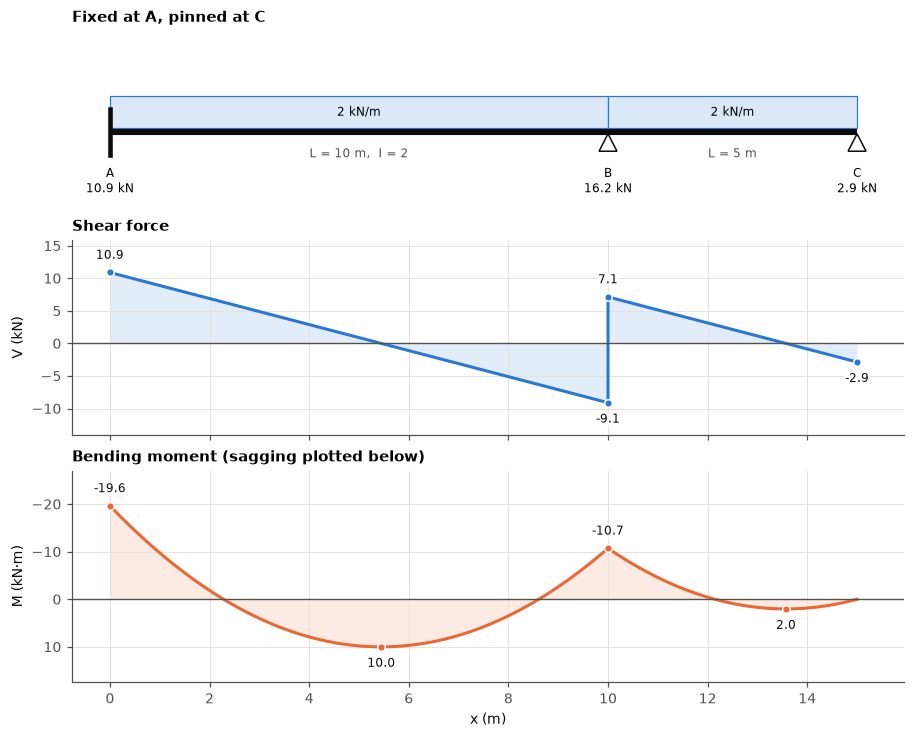

In [5]:
cb = ContinuousBeam([Span(10, [UDL(2)], I=2), Span(5, [UDL(2)], I=1)], left="fixed")
M = cb.three_moment(); cb.diagrams()
s = Sheet("Propped two-span beam", element="Three-moment equation")
for n, e in cb.equations:
    s.note(f"Support {n}: ${e}$", "NPTEL L12, imaginary span at the fixed end")
s.let("M_A", float(M[0]), "kN·m"); s.let("M_B", float(M[1]), "kN·m")
s.note("These are the same two equations as NPTEL (4) and (5). The printed NPTEL answer (−37.5, −6.25) does not satisfy its own equations: 20(−37.5) + 10(−6.25) = −812.5, not −500. The values here satisfy both, and moment distribution (Notebook 1.3) gives the same result.")
s.show("Equations and solution")
P.continuous(cb, "Fixed at A, pinned at C")